# 20. Bilder als Daten

Ein digitales Bild ist ein Raster aus winzigen Farbpunkten, den **Pixeln**. Jedes Pixel hat drei Zahlen von 0 bis 255: wie
viel **Rot**, **Grün** und **Blau** darin steckt (kurz **RGB**). Für den Computer ist ein Bild also eine große Tabelle mit
Zahlen, und mit Tabellen kennst du dich aus (Notebook 11 und 12).

In diesem Notebook lernst du:

- wie Farben als RGB-Werte funktionieren (wie der Blockly-Block „Farbe aus rot … grün … blau …“),
- wie du mit der Bibliothek **Pillow** Bilder erzeugst, liest und veränderst,
- wie ein Bild als lange Liste von Zahlen gespeichert sein kann.

In der Wettbewerbs-Ecke liest du die geheimen Nachrichten aus den echten Bildern der Aufgabe „St. Egano“.

## 1. Farben als RGB

| Farbe | Rot | Grün | Blau |
|---|---|---|---|
| Schwarz | 0 | 0 | 0 |
| Weiß | 255 | 255 | 255 |
| Rot | 255 | 0 | 0 |
| Gelb | 255 | 255 | 0 |
| Grau | 128 | 128 | 128 |
| Orange | 255 | 165 | 0 |

In Python schreibt man eine Farbe als `(255, 165, 0)`. Das ist ein **Tupel**: wie eine Liste, aber mit runden Klammern und
**unveränderlich**. Du kannst die Werte mit `farbe[0]` lesen oder mit `r, g, b = farbe` auf drei Variablen verteilen
(Notebook 7), aber nicht einzeln ändern.

Blockly hat einen Block „mische Farbe 1 und Farbe 2 im Verhältnis …“. Mischen heißt: Jeder der drei Werte liegt zwischen den
Werten der beiden Farben. Bei einem Verhältnis von 0.5 genau in der Mitte.

#### Aufgabe 1.1

Schreibe `mische(f1, f2, anteil)`, die eine neue Farbe zurückgibt: Bei `anteil = 0` ist es `f1`, bei `anteil = 1` ist es `f2`,
dazwischen wird gemischt. Jeder Wert ist `f1[i] * (1 - anteil) + f2[i] * anteil`, gerundet auf eine ganze Zahl.

**Erwartete Ausgabe:**
```
(128, 0, 128)
(191, 191, 191)
(255, 255, 0)
```

In [ ]:
def mische(f1, f2, anteil):
    return f1           # ersetze diese Zeile


print(mische((255, 0, 0), (0, 0, 255), 0.5))

<details>
<summary>Tipp anzeigen</summary>

Rechne die drei Werte einzeln aus und gib `(r, g, b)` zurück. `round` macht aus der Kommazahl eine ganze Zahl.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def mische(f1, f2, anteil):
    r = round(f1[0] * (1 - anteil) + f2[0] * anteil)
    g = round(f1[1] * (1 - anteil) + f2[1] * anteil)
    b = round(f1[2] * (1 - anteil) + f2[2] * anteil)
    return (r, g, b)


print(mische((255, 0, 0), (0, 0, 255), 0.5))
print(mische((255, 255, 255), (0, 0, 0), 0.25))
print(mische((255, 0, 0), (255, 255, 0), 1))
```

Rot und Blau ergeben halb und halb ein Lila `(128, 0, 128)`. Weiß mit einem Viertel Schwarz ergibt ein helles Grau.

</details>

## 2. Ein Bild erzeugen

Die Bibliothek **Pillow** heißt beim Importieren `PIL`. Die wichtigsten Befehle:

| Python | Bedeutung |
|---|---|
| `from PIL import Image` | einmal am Anfang |
| `bild = Image.new('RGB', (breite, hoehe), farbe)` | neues Bild, ganz in einer Farbe |
| `bild.putpixel((x, y), farbe)` | ein Pixel setzen |
| `bild.getpixel((x, y))` | Farbe eines Pixels lesen |
| `bild.size` oder `bild.width`, `bild.height` | Größe |

Achtung: Bei Pillow kommt **zuerst x** (Spalte), **dann y** (Zeile), und y = 0 ist **oben**. Das ist anders als bei
`tabelle[z][s]` (zuerst die Zeile)!

Zum Anzeigen benutzen wir hier eine kleine Funktion `zeige`, die das Bild mit matplotlib (Notebook 19) groß darstellt. Kleine
Bilder sind sonst nur ein paar Punkte groß. (Im Notebook kannst du ein Bild auch einfach als letzte Zeile einer Zelle hinschreiben.)

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt


def zeige(bild):
    plt.figure(figsize=(4, 3))
    plt.imshow(bild, interpolation='nearest')
    plt.axis('off')
    plt.show()


bild = Image.new('RGB', (6, 4), (255, 255, 255))
bild.putpixel((0, 0), (255, 0, 0))
bild.putpixel((5, 3), (0, 0, 255))
bild.putpixel((2, 1), (0, 160, 0))
print(bild.size, bild.getpixel((2, 1)))
zeige(bild)

#### Aufgabe 2.1

Zeichne ein Schachbrett aus 8 × 8 Pixeln: Ein Pixel ist schwarz, wenn `x + y` gerade ist, sonst weiß.

**So etwa sollte dein Bild aussehen:**

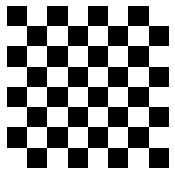

In [ ]:
bild = Image.new('RGB', (8, 8), (255, 255, 255))
# dein Code
zeige(bild)

<details>
<summary>Tipp anzeigen</summary>

Zwei Schleifen über `x` und `y`, darin `if (x + y) % 2 == 0:` und `bild.putpixel((x, y), (0, 0, 0))`.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
bild = Image.new('RGB', (8, 8), (255, 255, 255))
for x in range(8):
    for y in range(8):
        if (x + y) % 2 == 0:
            bild.putpixel((x, y), (0, 0, 0))
zeige(bild)
```

</details>

#### Aufgabe 2.2

Zeichne einen **Farbverlauf** von 50 × 10 Pixeln: Ganz links blau `(0, 0, 255)`, ganz rechts orange `(255, 165, 0)`. Jede Spalte
`x` bekommt die Mischung mit dem Anteil `x / 49`. Benutze `mische` aus Aufgabe 1.1.

**So etwa sollte dein Bild aussehen:**

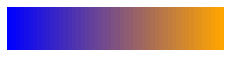

In [ ]:
bild = Image.new('RGB', (50, 10))
# dein Code
zeige(bild)

<details>
<summary>Tipp anzeigen</summary>

Für jede Spalte `x` einmal die Farbe ausrechnen, dann alle 10 Pixel dieser Spalte damit füllen.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
bild = Image.new('RGB', (50, 10))
for x in range(50):
    farbe = mische((0, 0, 255), (255, 165, 0), x / 49)
    for y in range(10):
        bild.putpixel((x, y), farbe)
zeige(bild)
```

</details>

## 3. Ein Bild lesen und verändern

`Image.open('dateiname.png')` lädt ein Bild aus einer Datei. Manche Bilder haben noch einen vierten Wert pro Pixel für die
Durchsichtigkeit (Modus `'RGBA'`). Mit `.convert('RGB')` wandelst du sie um, dann hat jedes Pixel sicher genau drei Werte.

Das Bild `daten/stegano_bild03.png` ist ein Foto vom Rhein bei Bonn, 75 × 50 Pixel klein. (Quelle: pixabay, siehe
`daten/stegano_bild3_quelle.txt`.)

In [ ]:
foto = Image.open('daten/stegano_bild03.png').convert('RGB')
print(foto.size, foto.mode)
print('Pixel oben links:', foto.getpixel((0, 0)))
zeige(foto)

#### Aufgabe 3.1

Berechne die **Durchschnittsfarbe** des Fotos: den Durchschnitt aller Rot-, aller Grün- und aller Blauwerte, auf ganze Zahlen
gerundet.

**Erwartete Ausgabe:**
```
3750 Pixel, Durchschnitt: 130 116 107
```

In [ ]:
summe_r = 0
summe_g = 0
summe_b = 0
# dein Code

<details>
<summary>Tipp anzeigen</summary>

Zwei Schleifen über alle Pixel, `r, g, b = foto.getpixel((x, y))` und drei Summen. Am Ende jede Summe durch die Anzahl der Pixel
teilen.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
summe_r = 0
summe_g = 0
summe_b = 0
for x in range(foto.width):
    for y in range(foto.height):
        r, g, b = foto.getpixel((x, y))
        summe_r = summe_r + r
        summe_g = summe_g + g
        summe_b = summe_b + b
anzahl = foto.width * foto.height
print(anzahl, 'Pixel, Durchschnitt:', round(summe_r / anzahl), round(summe_g / anzahl), round(summe_b / anzahl))
```

</details>

#### Aufgabe 3.2

Erzeuge eine **Graustufen-Version** des Fotos: ein neues Bild gleicher Größe, in dem jedes Pixel den Grauwert
`(r + g + b) // 3` in allen drei Farben bekommt.

**So etwa sollte dein Bild aussehen:**

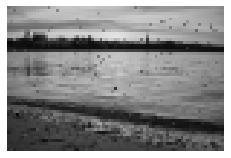

In [ ]:
grau = Image.new('RGB', foto.size)
# dein Code
zeige(grau)

<details>
<summary>Tipp anzeigen</summary>

Wie in Aufgabe 3.1 alle Pixel durchgehen, den Grauwert `w` ausrechnen und mit `grau.putpixel((x, y), (w, w, w))` setzen. Aus dem
alten Bild lesen, in das neue schreiben (Notebook 13).

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
grau = Image.new('RGB', foto.size)
for x in range(foto.width):
    for y in range(foto.height):
        r, g, b = foto.getpixel((x, y))
        w = (r + g + b) // 3
        grau.putpixel((x, y), (w, w, w))
zeige(grau)
```

</details>

## 4. Ein Bild als lange Liste von Zahlen

Es gibt auch Bildformate, die reiner **Text** sind. Beim Format **PPM (P3)** steht in der Datei zuerst `P3`, dann Breite und
Höhe, dann der größte Farbwert 255, und danach für jedes Pixel drei Zahlen, Zeile für Zeile von oben links. So sieht der Anfang
von `daten/stegano_bild01.ppm` aus:

```
P3
16 12
255
72 231 237 178 192 211 160 176 202 184 197 214 184 196 213
...
```

So eine Datei liest du ohne Bildbibliothek mit `split()` (Notebook 8). Dann hast du eine **lange Liste**: Die ersten vier
Einträge sind `P3`, Breite, Höhe und 255, danach kommen die Farbwerte. Das Pixel mit der Nummer `pos = y * breite + x`
(Notebook 11) beginnt in der Liste an der Stelle `4 + 3 * pos`.

#### Aufgabe 4.1

Lies `daten/stegano_bild01.ppm` als lange Liste ein und schreibe `pixel_ppm(werte, breite, x, y)`, die `(r, g, b)` zurückgibt.
Prüfe für ein paar Pixel, ob dasselbe herauskommt wie bei `getpixel` mit der PNG-Datei (zwei Wege vergleichen, Notebook 14).

**Erwartete Ausgabe:**
```
16 12 576
0 0 (72, 231, 237) (72, 231, 237)
5 2 (165, 180, 202) (165, 180, 202)
15 11 (82, 65, 34) (82, 65, 34)
```

In [ ]:
with open('daten/stegano_bild01.ppm', encoding='utf-8') as f:
    teile = f.read().split()
breite = int(teile[1])
hoehe = int(teile[2])
werte = []
for t in teile[4:]:
    werte.append(int(t))


def pixel_ppm(werte, breite, x, y):
    return (0, 0, 0)    # ersetze diese Zeile


png = Image.open('daten/stegano_bild01.png').convert('RGB')
print(breite, hoehe, len(werte))

<details>
<summary>Tipp anzeigen</summary>

Weil `werte` schon ohne die ersten vier Einträge gespeichert ist, beginnt Pixel `pos` bei `3 * pos`. Gib die drei Zahlen ab dort
als Tupel zurück.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
with open('daten/stegano_bild01.ppm', encoding='utf-8') as f:
    teile = f.read().split()
breite = int(teile[1])
hoehe = int(teile[2])
werte = []
for t in teile[4:]:
    werte.append(int(t))


def pixel_ppm(werte, breite, x, y):
    i = 3 * (y * breite + x)
    return (werte[i], werte[i + 1], werte[i + 2])


png = Image.open('daten/stegano_bild01.png').convert('RGB')
print(breite, hoehe, len(werte))
for x, y in [(0, 0), (5, 2), (15, 11)]:
    print(x, y, pixel_ppm(werte, breite, x, y), png.getpixel((x, y)))
```

Die Liste hat 16 · 12 · 3 = 576 Zahlen, drei für jedes Pixel. Beide Wege liefern dieselben Farben. In der Aufgabe „St. Egano“
gab es die Bilder als PNG und als PPM. Mit PPM kommt man ganz ohne Bildbibliothek aus.

</details>

## Wettbewerbs-Ecke: St. Egano, mit den echten Bildern

*Angelehnt an die Junioraufgabe „St. Egano“ (Jugendwettbewerb 2023).*

In Notebook 11 hast du die Nachricht aus einem selbst gebauten Mini-Bild gelesen. Jetzt nimmst du die echten Bilder der
Aufgabe. Zur Erinnerung: Man beginnt beim Pixel oben links. `r` ist der Zeichencode des nächsten Zeichens (`chr(r)`), `g` sagt,
wie weit es nach rechts geht, `b`, wie weit nach unten, beides im Kreis über den Bildrand (`%`). Sind `g` und `b` beide 0, ist
die Nachricht zu Ende.

#### Aufgabe E.1

Schreibe `lies_nachricht(dateiname)`, die das Bild öffnet (mit `.convert('RGB')`), die Nachricht entschlüsselt und zurückgibt.
Wende sie auf `daten/stegano_bild01.png` an.

**Erwartete Ausgabe:**
```
Hallo Welt
```

In [ ]:
def lies_nachricht(dateiname):
    return ''           # ersetze diese Zeile


print(lies_nachricht('daten/stegano_bild01.png'))

<details>
<summary>Tipp anzeigen</summary>

Wie in Notebook 11, Aufgabe E.3, nur mit `bild.getpixel((x, y))` statt `bild[y][x]` und mit `bild.width` und `bild.height`.
Statt `break` kannst du in der Funktion gleich `return nachricht` schreiben.

</details>

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def lies_nachricht(dateiname):
    bild = Image.open(dateiname).convert('RGB')
    x = 0
    y = 0
    nachricht = ''
    while True:
        r, g, b = bild.getpixel((x, y))
        nachricht = nachricht + chr(r)
        if g == 0 and b == 0:
            return nachricht
        x = (x + g) % bild.width
        y = (y + b) % bild.height


print(lies_nachricht('daten/stegano_bild01.png'))
```

</details>

#### Aufgabe E.2

Lies die Nachrichten aus `daten/stegano_bild02.png` und `daten/stegano_bild03.png`. Sie bilden zusammen ein kleines Gespräch.

**Erwartete Ausgabe:**
```
Hallo Gloria

Wie treffen uns am Freitag um 15:00 Uhr vor der Eisdiele am Markplatz.

Alle Liebe,
Juliane
---
Hallo Juliane,

Super, ich werde da sein! Ich freue mich schon auf den riesen Eisbecher mit Erdbeeren. 

Bis bald,
Gloria
```

In [ ]:
# dein Code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
print(lies_nachricht('daten/stegano_bild02.png'))
print('---')
print(lies_nachricht('daten/stegano_bild03.png'))
```

Die Nachrichten enthalten Zeilenumbrüche (Zeichencode 10), die `print` als neue Zeilen ausgibt. In der echten Aufgabe gibt es
noch vier größere Bilder, das größte mit fast 4 Millionen Pixeln. Die Nachricht im letzten enthält sogar ein „ß“
(Zeichencode 223). Alle findest
du in `jwinf3/42_StEgano/stegano_loesung.ipynb`.

</details>

## Das hast du gelernt

| Python | Bedeutung |
|---|---|
| `(r, g, b)` | eine Farbe als Tupel, jeder Wert von 0 bis 255 |
| `from PIL import Image` | Pillow laden |
| `Image.new('RGB', (b, h), farbe)` | neues Bild |
| `Image.open(name).convert('RGB')` | Bild aus einer Datei laden, sicher mit drei Werten pro Pixel |
| `bild.getpixel((x, y))`, `bild.putpixel((x, y), farbe)` | Pixel lesen und setzen, **erst x, dann y** |
| `bild.width`, `bild.height`, `bild.size` | Größe |
| PPM als Text | `split()`, Pixel `pos = y * breite + x` beginnt bei `3 * pos` |

- Bilder sind Tabellen aus Farben: alles aus den Notebooks 11 bis 13 funktioniert auch hier.
- Beim Verändern aus dem alten Bild lesen und in ein neues schreiben.

Weiter geht es mit den freiwilligen Notebooks 21 (Erreichbarkeit) und 22 (Rekursion).